# Figure 5: CEBRA Population Manifold Analysis

**Paper**: Parodi et al. (2026)

This notebook reproduces Figure 5, which uses CEBRA (v0.4.0) to learn nonlinear neural manifolds and assess:
- **Panel C**: Height and motif decoding from CEBRA embeddings vs PCA vs raw neural activity
- **Panel D**: Transition dynamics — neural velocity increases at behavioral state transitions
- **Panel E**: Context-dependent coding — same behavior encoded differently at different spatial locations

**CEBRA** is a self-supervised contrastive learning method that finds low-dimensional neural embeddings aligned with behavioral labels.

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
})

SESSIONS = ["M2_0526", "M2_0605", "M1_0525", "M1_0609", "M1_0613"]
FIG5_DIR = REPO_ROOT / "results" / "fig5_cebra"
print("Setup complete.")

Setup complete.


## Publication Figure (Production Results)

*Panel A schematic: CEBRA pipeline diagram (to be added in figure assembly)*

In [2]:
# Load production data using pub_data loaders
from freemat.single_fm.viz.pub_data import load_fig5_results, load_fig5_embeddings

fig5_results = load_fig5_results()
fig5_emb = load_fig5_embeddings("M2_0526")

print(f"Results loaded for {len(fig5_results)} sessions: {list(fig5_results.keys())}")
print(f"Embeddings keys: {list(fig5_emb.keys())[:5]}")

# Check what dynamics data is available in results
sample = fig5_results.get("M2_0526", {})
print(f"\nM2_0526 result keys: {list(sample.keys())[:10]}")

Results loaded for 5 sessions: ['M2_0526', 'M2_0605', 'M1_0525', 'M1_0609', 'M1_0613']
Embeddings keys: ['emb_spatial_viz_3d', 'emb_behavior_viz_3d', 'emb_behavior_viz_8d', 'emb_time_3d', 'emb_pca_8d']

M2_0526 result keys: ['session_id', 'config', 'coverage', 'decode_results', 'dynamics_cebra', 'dynamics_pca', 'context_cebra', 'context_pca', 'robustness', 'claim_evidence']


### Figure 5 Composite (Publication Layout)

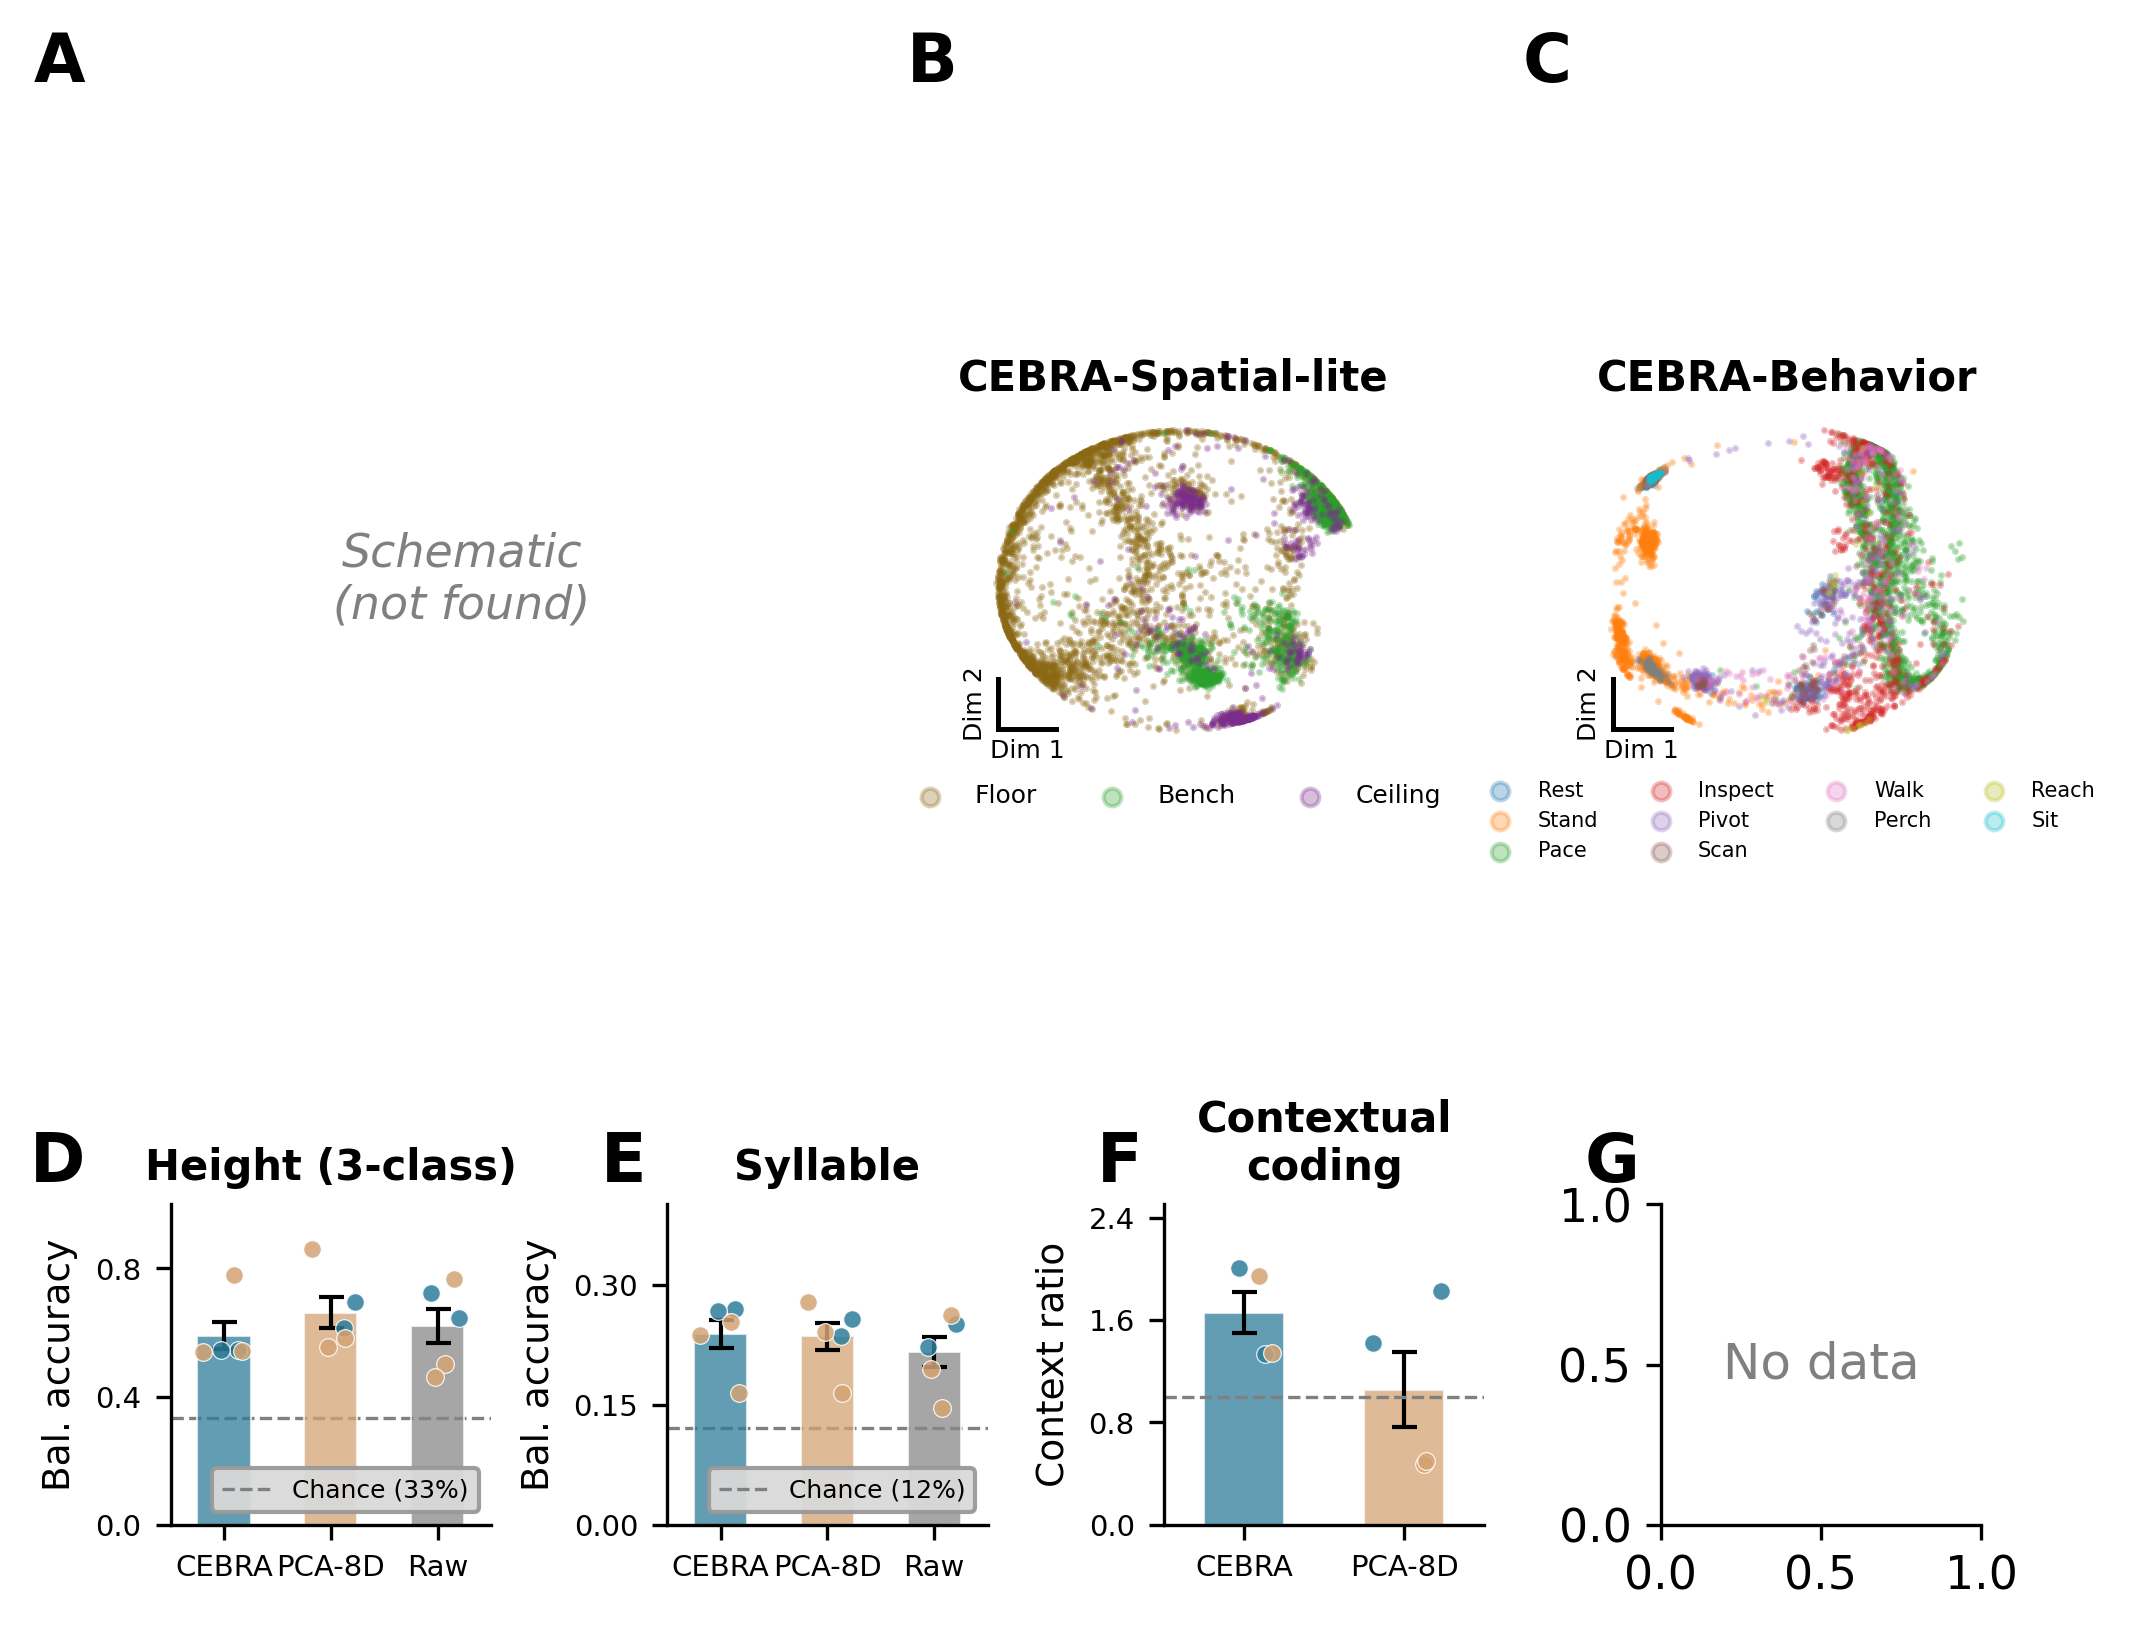

In [3]:
from freemat.single_fm.viz.fig5_composite import fig5_composite

fig = fig5_composite(
    fig5_results=fig5_results,
    fig5_embeddings={"M2_0526": fig5_emb},
    manifold_results=[],  # Optional follow-up analyses
    primary_session="M2_0526",
)
plt.show()